# Lei dos Grandes Números com dados de estudantes

## Pergunta da aula

Ao observar apenas uma amostra de estudantes, a proporção de aprovados se parece com a proporção encontrada no conjunto completo? O que muda quando aumentamos o tamanho da amostra?

Nesta aula executável, vamos gerar um **dataset sintético** com 1.000 estudantes. Isso significa que os registros foram simulados exclusivamente para fins didáticos: eles não representam uma escola nem pessoas reais.

Percorreremos uma sequência simples: gerar e inspecionar os dados, criar a variável-alvo binária, calcular a proporção no conjunto completo, retirar quatro amostras, comparar, visualizar e interpretar os resultados.

## 1. Preparação e reprodutibilidade

**O que faremos e por quê?** Importaremos somente `numpy`, `pandas` e `matplotlib`. Uma semente fixa controla a geração aleatória, fazendo com que cada execução completa produza exatamente o mesmo dataset.

**Como o código funciona?** `default_rng` cria um gerador aleatório independente e reproduzível. Também definimos o número de estudantes em um nome descritivo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMENTE_DADOS = 42
NUMERO_ESTUDANTES = 1000
gerador = np.random.default_rng(SEMENTE_DADOS)

print(f"Semente dos dados: {SEMENTE_DADOS}")
print(f"Número planejado de estudantes: {NUMERO_ESTUDANTES}")

Semente dos dados: 42
Número planejado de estudantes: 1000


**Interpretação do resultado.** A saída registra as duas escolhas que tornam o experimento verificável. Reprodutibilidade é importante porque permite que outra pessoa confira os mesmos números.

## 2. Geração do dataset sintético

**O que faremos?** Para cada estudante, simularemos horas de estudo por semana, número de faltas, idade e nota final.

**Por que esta etapa existe?** O exercício não fornece dados. Para concluir a tarefeça foi escolhido ter 1.000 registros plausíveis, com a nota relacionada positivamente ao estudo e negativamente às faltas. A idade será apenas uma característica: ela não aparece na fórmula da nota.

**Como o código funciona?** As horas são geradas em uma faixa de 0 a 20, as faltas entre 0 e 20 e a idade entre 17 e 30. A nota combina uma base, `2.5 × horas de estudo`, `-1.5 × faltas` e um ruído individual. `np.clip` garante notas entre 0 e 100. Os arredondamentos facilitam a leitura, sem alterar a lógica do experimento.

In [2]:
horas_estudo_semana = gerador.uniform(0, 20, NUMERO_ESTUDANTES)
numero_faltas = gerador.integers(0, 21, NUMERO_ESTUDANTES)
idade = gerador.integers(17, 31, NUMERO_ESTUDANTES)
variabilidade_individual = gerador.normal(0, 10, NUMERO_ESTUDANTES)

nota_sem_limites = (
    45
    + 2.5 * horas_estudo_semana
    - 1.5 * numero_faltas
    + variabilidade_individual
)
nota_final = np.clip(nota_sem_limites, 0, 100)

estudantes = pd.DataFrame({
    "horas_estudo_semana": horas_estudo_semana.round(1),
    "numero_faltas": numero_faltas,
    "nota_final": nota_final.round(1),
    "idade": idade,
})

print(estudantes.head().to_string(index=False))

 horas_estudo_semana  numero_faltas  nota_final  idade
                15.5             18        46.5     27
                 8.8              1        74.5     26
                17.2              8        63.9     30
                13.9              9        63.5     30
                 1.9             16        19.8     26


**Interpretação do resultado.** Cada linha representa um estudante sintético. As quatro variáveis solicitadas estão presentes. É importante não interpretar essas relações simuladas como conclusões sobre estudantes reais.

## 3. Inspeção e validação dos dados

**O que faremos e por quê?** Verificaremos dimensões, tipos e limites. Os `assert` interrompem a execução se uma regra essencial for violada e, por isso, ensinam uma prática simples de controle de qualidade.

In [3]:
print(f"Dimensões do dataset: {estudantes.shape[0]} linhas e {estudantes.shape[1]} colunas")
print(estudantes.describe().round(2).to_string())

assert len(estudantes) == 1000, "O dataset deve possuir exatamente 1.000 estudantes."
assert estudantes["nota_final"].between(0, 100).all(), "As notas devem estar entre 0 e 100."
assert estudantes["idade"].between(17, 30).all(), "As idades devem estar entre 17 e 30."
assert estudantes.notna().all().all(), "O dataset não deve conter valores ausentes."

print("Validações da geração concluídas com sucesso.")

Dimensões do dataset: 1000 linhas e 4 colunas
       horas_estudo_semana  numero_faltas  nota_final    idade
count              1000.00        1000.00     1000.00  1000.00
mean                  9.94          10.07       54.91    23.51
std                   5.83           6.06       19.45     3.98
min                   0.00           0.00        0.00    17.00
25%                   4.80           5.00       41.75    20.00
50%                   9.90          10.00       55.40    23.50
75%                  15.20          15.00       68.40    27.00
max                  20.00          20.00      100.00    30.00
Validações da geração concluídas com sucesso.


**Interpretação do resultado.** Temos exatamente 1.000 estudantes, notas no intervalo permitido, idades plausíveis e nenhum valor ausente. A idade foi gerada separadamente e não influencia a nota.

## 4. Criação da variável-alvo binária

**O que faremos?** Criaremos `aprovado`: valor 1 para nota maior ou igual a 60 e 0 para nota menor que 60.

**Conexão com aprendizado de máquina.** Essa coluna tem a forma de uma variável-alvo binária frequentemente usada em aprendizado supervisionado. Aqui, porém, ela é definida por uma regra determinística; **nenhum modelo de Machine Learning será treinado**.

**Como o código funciona?** A comparação produz `True` ou `False`; `astype(int)` converte esses valores em 1 ou 0.

In [4]:
estudantes["aprovado"] = (estudantes["nota_final"] >= 60).astype(int)

print(estudantes[["nota_final", "aprovado"]].head(10).to_string(index=False))

assert set(estudantes["aprovado"].unique()).issubset({0, 1})
assert (estudantes["aprovado"] == (estudantes["nota_final"] >= 60).astype(int)).all()
print("Regra de aprovação validada com sucesso.")

 nota_final  aprovado
       46.5         0
       74.5         1
       63.9         1
       63.5         1
       19.8         0
       92.4         1
       63.2         1
       77.1         1
       25.0         0
       40.7         0
Regra de aprovação validada com sucesso.


**Interpretação do resultado.** A tabela permite conferir diretamente a regra: cada nota a partir de 60 recebe 1, e cada nota abaixo de 60 recebe 0.

## 5. Proporção de aprovados no conjunto completo

**Intuição primeiro.** Somar a coluna `aprovado` conta os aprovados. Dividir pelo total produz a proporção. Como uma coluna de zeros e uns tem média igual à soma dividida pela quantidade, `mean()` calcula diretamente essa proporção.

Neste experimento, os 1.000 registros formam a nossa população de referência. Chamaremos sua proporção de aprovados de $p$.

In [5]:
total_aprovados = int(estudantes["aprovado"].sum())
proporcao_populacao = estudantes["aprovado"].mean()

print(f"Aprovados no conjunto completo: {total_aprovados} de {len(estudantes)}")
print(f"Proporção no conjunto completo (p): {proporcao_populacao:.3f} ({proporcao_populacao:.1%})")

Aprovados no conjunto completo: 411 de 1000
Proporção no conjunto completo (p): 0.411 (41.1%)


**Interpretação do resultado.** Essa proporção é a referência que tentaremos estimar usando menos estudantes. Ela não é uma verdade sobre todas as escolas; é apenas o valor do conjunto sintético completo.

## 6. Uma amostra aleatória para cada tamanho

**O que faremos?** Retiraremos exatamente uma amostra aleatória de cada tamanho oficial: 10, 50, 100 e 500. Cada amostra recebe uma semente fixa própria.

**Por que sementes diferentes?** Elas mantêm cada sorteio reproduzível sem exigir que uma amostra esteja contida na seguinte. Não escolhemos sementes para forçar uma aproximação monotônica.

**Como o código funciona?** `sample(n=..., random_state=...)` sorteia linhas sem reposição. A média de `aprovado` em cada amostra é sua proporção $\hat p_n$.

In [6]:
tamanhos_amostra = [10, 50, 100, 500]
sementes_amostras = {10: 110, 50: 150, 100: 200, 500: 600}
resultados = []

for tamanho in tamanhos_amostra:
    amostra = estudantes.sample(
        n=tamanho,
        random_state=sementes_amostras[tamanho],
        replace=False,
    )
    proporcao_amostra = amostra["aprovado"].mean()
    resultados.append({
        "tamanho_amostra": tamanho,
        "aprovados": int(amostra["aprovado"].sum()),
        "proporcao_amostra": proporcao_amostra,
        "diferenca_absoluta": abs(proporcao_amostra - proporcao_populacao),
    })

comparacao = pd.DataFrame(resultados)
comparacao["proporcao_populacao"] = proporcao_populacao

assert comparacao["tamanho_amostra"].tolist() == [10, 50, 100, 500]
assert comparacao["proporcao_amostra"].between(0, 1).all()
assert comparacao["aprovados"].between(0, comparacao["tamanho_amostra"]).all()

print(comparacao.round(3).to_string(index=False))

 tamanho_amostra  aprovados  proporcao_amostra  diferenca_absoluta  proporcao_populacao
              10          6              0.600               0.189                0.411
              50         18              0.360               0.051                0.411
             100         42              0.420               0.009                0.411
             500        191              0.382               0.029                0.411


**Interpretação do resultado.** A coluna `diferenca_absoluta` mede a distância entre cada proporção amostral e a referência. Uma amostra pequena pode, por acaso, ficar perto de $p$, e uma amostra maior pode não melhorar em relação à anterior. A Lei dos Grandes Números descreve uma tendência estatística, não uma aproximação obrigatoriamente monotônica em quatro sorteios isolados.

## 7. Visualização da comparação

**O que faremos e por quê?** Colocaremos o tamanho da amostra no eixo X e a proporção de aprovados no eixo Y. A curva mostra os quatro resultados; a linha horizontal tracejada representa a proporção do conjunto completo.

O gráfico transforma a tabela em uma comparação visual direta.

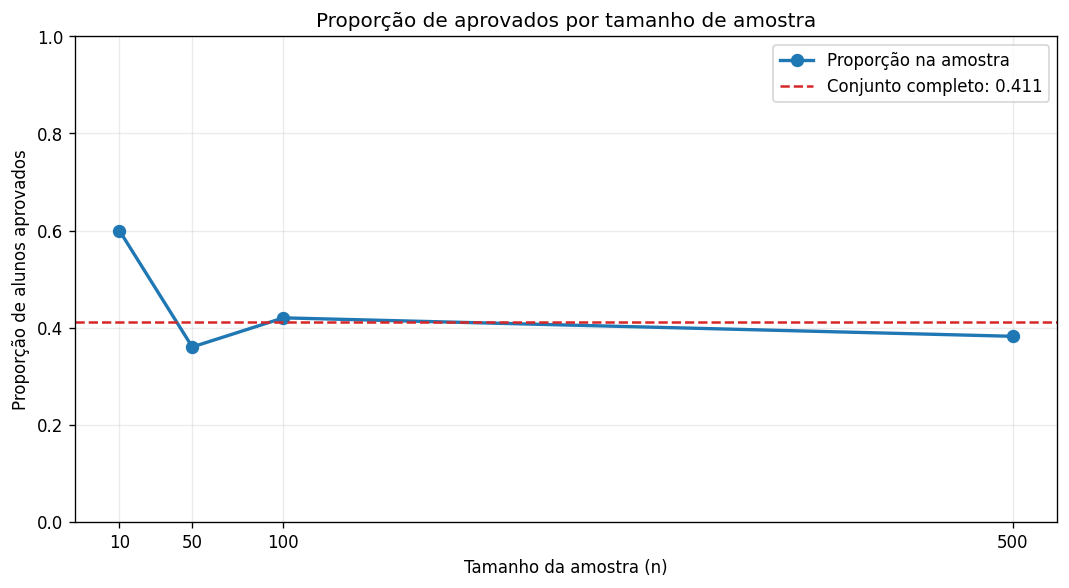

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(
    comparacao["tamanho_amostra"],
    comparacao["proporcao_amostra"],
    marker="o",
    linewidth=2,
    markersize=7,
    label="Proporção na amostra",
)
ax.axhline(
    proporcao_populacao,
    color="tab:red",
    linestyle="--",
    label=f"Conjunto completo: {proporcao_populacao:.3f}",
)
ax.set_xticks(tamanhos_amostra)
ax.set_xlabel("Tamanho da amostra (n)")
ax.set_ylabel("Proporção de alunos aprovados")
ax.set_title("Proporção de aprovados por tamanho de amostra")
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

**Interpretação do gráfico.** Os pontos não precisam caminhar em linha reta até a referência. O aspecto importante é que amostras maiores tendem, em muitas repetições do experimento, a apresentar menor flutuação em torno da proporção da população.

## 8. Lei dos Grandes Números: da intuição à matemática

### Intuição

Em uma amostra de 10 estudantes, uma única pessoa representa 10% do resultado. Em uma amostra de 500, uma pessoa representa apenas 0,2%. Assim, resultados individuais exercem menos influência sobre a proporção agregada quando observamos mais pessoas. Amostras pequenas ficam mais expostas ao acaso; amostras grandes tendem a ser mais estáveis.

### Interpretação matemática

Definimos, para cada estudante,

$$
X_i =
\begin{cases}
1, & \text{se o estudante foi aprovado} \\
0, & \text{se o estudante foi reprovado.}
\end{cases}
$$

A média de uma amostra de tamanho $n$ é

$$
\bar X_n = \frac{X_1 + X_2 + \cdots + X_n}{n}.
$$

Como $X_i$ só assume 0 ou 1, essa média é exatamente a proporção amostral de aprovados: $\hat p_n = \bar X_n$. A Lei dos Grandes Números afirma que

$$
\hat p_n \rightarrow p \quad \text{quando} \quad n \rightarrow \infty.
$$

Além disso, para observações independentes com variância $\sigma^2$,

$$
\operatorname{Var}(\bar X_n) = \frac{\sigma^2}{n}.
$$

O denominador mostra por que a variabilidade da média diminui quando $n$ cresce. Isso não promete que cada amostra maior ficará mais próxima de $p$ do que a anterior; descreve a redução da variabilidade no comportamento de muitas amostras.

## 9. Relatório final — sem código

### Objetivo e dados

Este experimento investigou como o tamanho de uma amostra afeta a estimativa da proporção de alunos aprovados. Foi utilizado um **dataset sintético e reproduzível** de 1.000 estudantes, com horas de estudo por semana, número de faltas, nota final e idade. Considerou-se aprovado o estudante com nota final maior ou igual a 60.

### Resultados

Os valores numéricos oficiais estão apresentados na tabela comparativa acima. Ela informa a proporção de aprovados no conjunto completo e, para uma amostra aleatória de cada tamanho (10, 50, 100 e 500), a quantidade e a proporção de aprovados, além da diferença absoluta em relação ao conjunto completo. O gráfico apresenta esses quatro resultados e usa a linha horizontal tracejada como referência da proporção completa.

### Conclusão

Os resultados ilustram a Lei dos Grandes Números: amostras pequenas estão mais sujeitas ao acaso, enquanto o aumento do número de observações tende a estabilizar a proporção em torno do valor da população. Eventuais oscilações entre tamanhos consecutivos não contradizem a lei, pois a convergência é um comportamento estatístico e não uma exigência de melhora monotônica em cada sorteio individual.